In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [50]:
df = pd.read_csv('../results/ite_tree_results_[1, 2, 3, 4, 5, 6]_1000_inverted.csv')
df.head()

,h,alpha,pr_satisfiable,avg_runtime
0,1,0.000000,0.999,0.000002
1,1,0.016003,1.000,0.000004
2,1,0.032006,1.000,0.000003
3,1,0.048010,0.999,0.000003
4,1,0.064013,0.997,0.000002


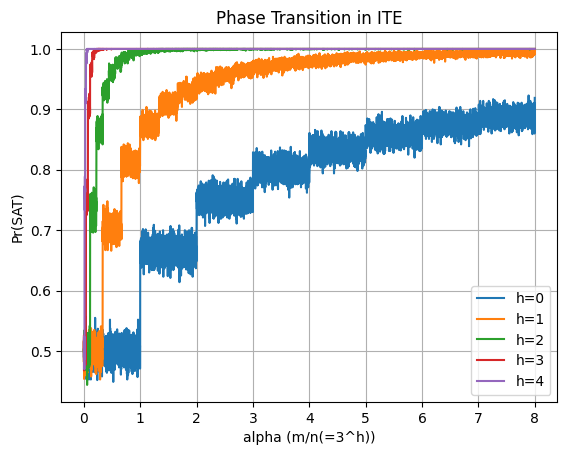

In [44]:
for n in df['h'].unique():
    subset = df[df['h'] == n]
    plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}')
    # plt.scatter(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}', s=1)
plt.xlabel('alpha (m/n(=3^h))')
plt.ylabel('Pr(SAT)')
plt.title('Phase Transition in ITE')
plt.legend()
plt.grid()
plt.show()

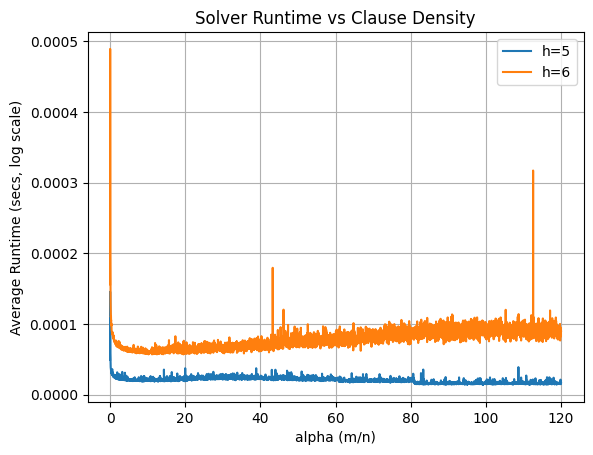

In [89]:
for n in df['h'].unique():
    subset = df[df['h'] == n]
    plt.plot(subset['alpha'], subset['avg_runtime'], label=f'h={n}')
# plt.yscale('log')
plt.xlabel('alpha (m/n)')
plt.ylabel('Average Runtime (secs, log scale)')
plt.title('Solver Runtime vs Clause Density')
plt.legend()
plt.grid()
plt.show()

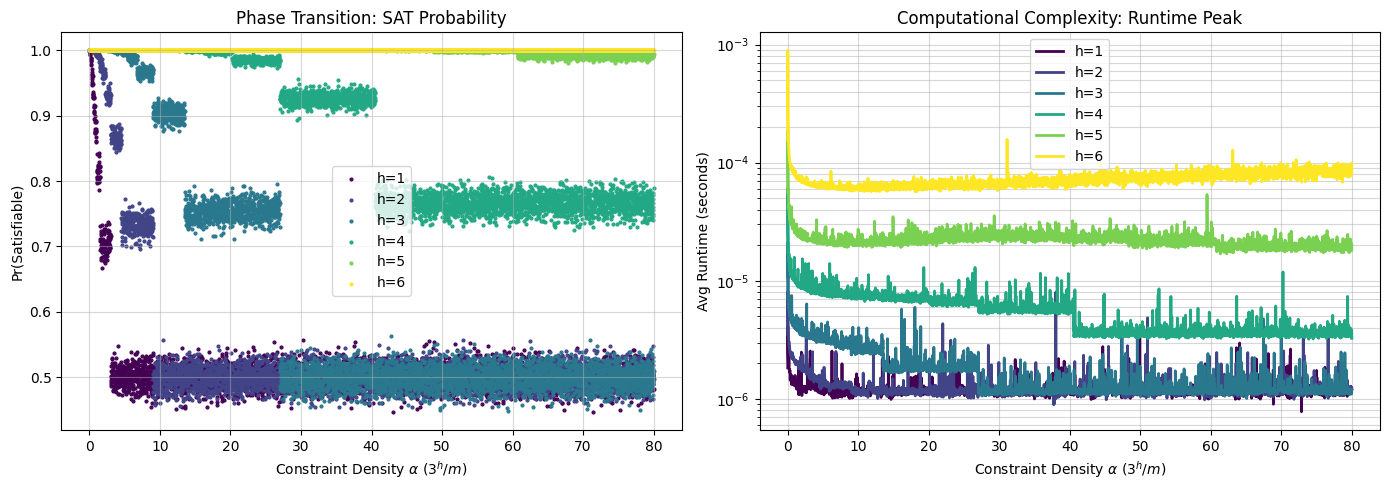

In [51]:
def plot_results(df):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Use a distinct color map for the different tree depths
    colors = plt.cm.viridis(np.linspace(0, 1, len(df['h'].unique())))

    for i, h_val in enumerate(sorted(df['h'].unique())):
        subset = df[df['h'] == h_val]
        
        # 1. Probability Plot
        ax1.scatter(subset['alpha'], subset['pr_satisfiable'], 
                 label=f'h={h_val}', color=colors[i], linewidth=2, s=1)
        
        # 2. Runtime Plot
        ax2.plot(subset['alpha'], subset['avg_runtime'], 
                 label=f'h={h_val}', color=colors[i], linewidth=2)

    # Styling the Probability Plot
    ax1.set_xlabel(r'Constraint Density $\alpha$ ($3^h / m$)')
    ax1.set_ylabel('Pr(Satisfiable)')
    ax1.set_title('Phase Transition: SAT Probability')
    ax1.grid(True, which="both", ls="-", alpha=0.5)
    ax1.legend()

    # Styling the Runtime Plot
    ax2.set_xlabel(r'Constraint Density $\alpha$ ($3^h / m$)')
    ax2.set_ylabel('Avg Runtime (seconds)')
    ax2.set_yscale('log') # CRITICAL: Shows exponential growth clearly
    ax2.set_title('Computational Complexity: Runtime Peak')
    ax2.grid(True, which="both", ls="-", alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.show()

plot_results(df)


In [40]:
df = pd.read_csv('../results/ite_tree_results_[10, 50, 100, 200]_1000.csv')
df.head()

,m,alpha,pr_satisfiable,avg_runtime
0,10,0.000000,0.907,0.000001
1,10,0.160032,1.000,0.000004
2,10,0.320064,1.000,0.000004
3,10,0.480096,0.995,0.000002
4,10,0.640128,0.998,0.000002


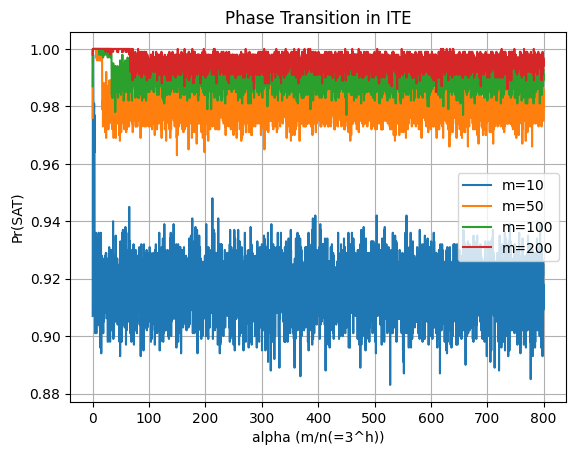

In [41]:
# # for n in df['h'].unique():
# #     subset = df[df['h'] == n]
# #     plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}')
# # plt.xlabel('alpha (m/n(=3^h))')
# # plt.ylabel('Pr(SAT)')
# # plt.title('Phase Transition in ITE')
# # plt.legend()
# # plt.grid()
# # plt.show()

# # plot of pr_satisfiable vs h, only one alpha = m = 3 in the csv
# # subset = df[df['m'] == 3]
# plt.plot(df['p_const'], df['pr_satisfiable'], marker='o')
# plt.xlabel('p_const')
# plt.ylabel('Pr(SAT)')
# plt.title('Pr(SAT) vs p_const for m=3')
# plt.grid()
# plt.show()

for n in df['m'].unique():
    subset = df[df['m'] == n]
    plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'm={n}')
    # plt.scatter(subset['alpha'], subset['pr_satisfiable'], label=f'm={n}', s=1)
plt.xlabel('alpha (m/n(=3^h))')
plt.ylabel('Pr(SAT)')
plt.title('Phase Transition in ITE')
plt.legend()
plt.grid()
plt.show()

In [35]:
df = pd.read_csv('../results/ite_tree_results_5_1000_mlog.csv')
df.head()

,h,alpha,pr_satisfiable,avg_runtime
0,1,0,0.510,0.000001
1,2,0,0.490,0.000001
2,3,0,0.514,0.000001
3,4,0,0.487,0.000001
4,5,0,0.492,0.000004


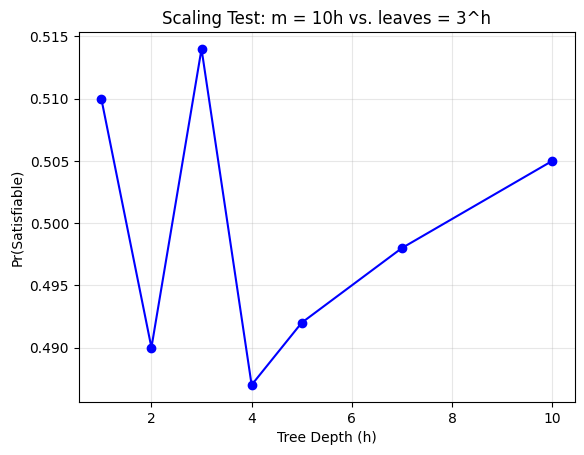

In [36]:
# Plotting logic for Experiment 1
plt.plot(df['h'], df['pr_satisfiable'], marker='o', linestyle='-', color='b')
plt.xlabel('Tree Depth (h)')
plt.ylabel('Pr(Satisfiable)')
plt.title('Scaling Test: m = 10h vs. leaves = 3^h')
plt.grid(True, alpha=0.3)
plt.show()




In [52]:
df = pd.read_csv('../results/ite_contingency_test_100_1000.csv')
df.head()

,h,pr_contingent,pr_tautology,pr_unsat,pr_sat_total
0,1,1.0,0.0,0.0,1.0
1,2,1.0,0.0,0.0,1.0
2,3,1.0,0.0,0.0,1.0
3,4,1.0,0.0,0.0,1.0
4,5,1.0,0.0,0.0,1.0


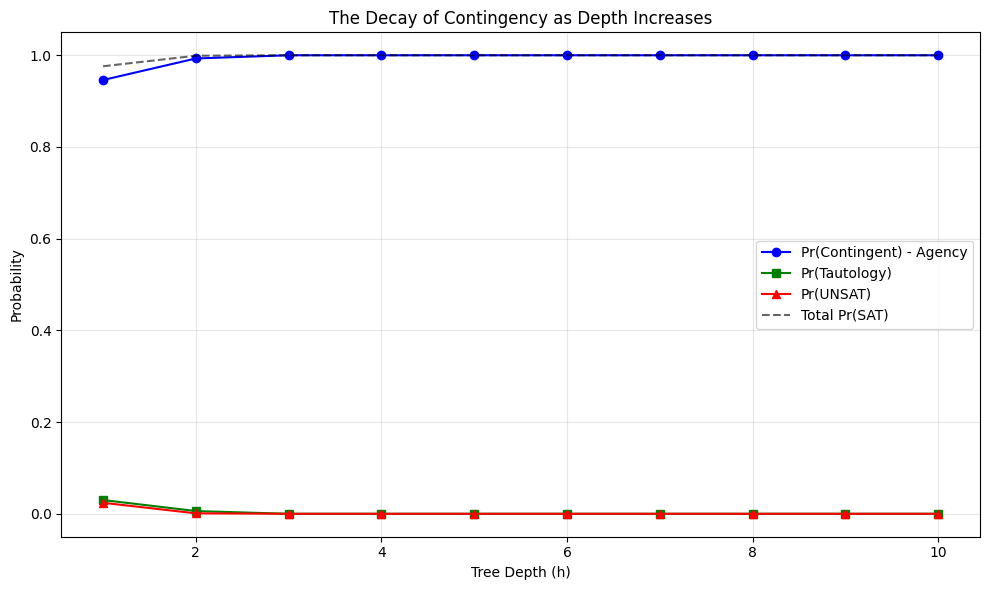

In [3]:
def plot_contingency(csv_file):
    df = pd.read_csv(csv_file)
    
    plt.figure(figsize=(10, 6))
    
    # 1. Contingent: Variables can change the outcome
    plt.plot(df['h'], df['pr_contingent'], label='Pr(Contingent) - Agency', marker='o', color='blue')
    
    # 2. Tautology: Forced True by structure
    plt.plot(df['h'], df['pr_tautology'], label='Pr(Tautology)', marker='s', color='green')
    
    # 3. UNSAT: Forced False by structure
    plt.plot(df['h'], df['pr_unsat'], label='Pr(UNSAT)', marker='^', color='red')
    
    # 4. Total Satisfiability (what you saw before)
    plt.plot(df['h'], df['pr_sat_total'], label='Total Pr(SAT)', linestyle='--', color='black', alpha=0.6)

    plt.xlabel('Tree Depth (h)')
    plt.ylabel('Probability')
    plt.title('The Decay of Contingency as Depth Increases')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_contingency("../results/csv/ite_contingency_test_10_1000.csv")
